In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from scipy.fft import fft, fftfreq, dct, rfft, rfftfreq
from scipy import signal
import IPython.display as ipd
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from scipy.fftpack import dct
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

In [ ]:
class BaseAudioFeature:
    def __init__(self, sample_rate=22050):
        self.sample_rate = sample_rate

    def preprocess(self, sig):
        if sig is None or len(sig) == 0:
            return sig
        sig = sig - np.mean(sig)
        sig = sig / (np.max(np.abs(sig)) + 1e-10)
        pre_emph = np.append(sig[0], sig[1:] - 0.97 * sig[:-1])
        return pre_emph

    def compute_fft_analysis(self, audio_signal):
        N = len(audio_signal)
        if N == 0:
            return np.array([]), np.array([]), 0
        yf = fft(audio_signal)
        xf = fftfreq(N, 1/self.sample_rate)[:N//2]
        magnitude = 2.0/N * np.abs(yf[0:N//2])
        return xf, magnitude, N

    def extract_dominant_frequency(self, signal, sr=None, low_cut=80.0):
        if sr is None:
            sr = self.sample_rate
        if signal is None or len(signal) == 0:
            return np.nan
        sig = signal - np.mean(signal)
        pre = 0.97
        emphasized = np.append(sig[0], sig[1:] - pre*sig[:-1])
        fft_vals = np.abs(rfft(emphasized))
        freqs = rfftfreq(len(emphasized), 1/sr)
        valid = freqs > low_cut
        if np.any(valid):
            vals = fft_vals[valid]; fr = freqs[valid]; idx = np.argmax(vals); return float(fr[idx])
        else:
            if len(fft_vals)==0:
                return np.nan
            idx = np.argmax(fft_vals)
            return float(freqs[idx])

    def compute_dct_features(self, audio_signal):
        if audio_signal is None or len(audio_signal) == 0:
            return {'dct_mean': np.nan, 'dct_std': np.nan, 'dct_energy': np.nan}, np.zeros(13)
        coeffs = dct(audio_signal, type=2, norm='ortho')
        first13 = coeffs[:13] if len(coeffs) >= 13 else np.pad(coeffs, (0, 13 - len(coeffs)))
        stats = {
            'dct_mean': float(np.mean(first13)),
            'dct_std': float(np.std(first13)),
            'dct_energy': float(np.sum(first13**2))
        }
        return stats, coeffs

    def compute_mfcc_features(self, audio_signal, n_mfcc=13):
        if audio_signal is None or len(audio_signal) == 0:
            mfccs = np.zeros((n_mfcc, 1))
        else:
            mfccs = librosa.feature.mfcc(y=audio_signal, sr=self.sample_rate, n_mfcc=n_mfcc)
        mfcc_stats = {}
        for i in range(mfccs.shape[0]):
            mfcc_stats[f'mfcc_{i+1}_mean'] = float(np.mean(mfccs[i]))
            mfcc_stats[f'mfcc_{i+1}_std']  = float(np.std(mfccs[i]))
        delta = librosa.feature.delta(mfccs)
        for i in range(delta.shape[0]):
            mfcc_stats[f'delta_mfcc_{i+1}_mean'] = float(np.mean(delta[i]))
        return mfcc_stats, mfccs

    def spectral_rolloff(self, magnitude, frequencies, percentile=85):
        if len(magnitude) == 0:
            return np.nan
        total_energy = np.sum(magnitude)
        cumulative = np.cumsum(magnitude)
        idx = np.searchsorted(cumulative, (percentile/100)*total_energy)
        return float(frequencies[min(idx, len(frequencies)-1)])

    def spectral_flux(self, magnitude):
        if len(magnitude) < 2:
            return 0.0
        return float(np.sum(np.diff(magnitude)**2))

    def band_energy_ratio(self, magnitude, frequencies, cutoff=1000):
        if len(magnitude) == 0:
            return np.nan
        low_mask = frequencies <= cutoff
        high_mask = frequencies > cutoff
        low_energy = np.sum(magnitude[low_mask]) if np.any(low_mask) else 0.0
        high_energy = np.sum(magnitude[high_mask]) if np.any(high_mask) else 0.0
        return float(low_energy / (high_energy + 1e-10))

In [ ]:
# ANALISIS PER FILE
class PerFileAnalyzer(BaseAudioFeature):
    def __init__(self, sample_rate=22050):
        super().__init__(sample_rate=sample_rate)
        self.signals = {}
        self.features = {}
        self.detail = {}

    def load_file(self, file_path):
        sig, sr = librosa.load(file_path, sr=self.sample_rate, mono=True)
        self.signals[file_path] = sig
        return sig

    def fft_features(self, sig):
        fft_vals = np.abs(rfft(sig))
        freqs = rfftfreq(len(sig), 1/self.sample_rate)
        mask = freqs > 80
        fft_vals2 = fft_vals[mask] if np.any(mask) else fft_vals
        freqs2 = freqs[mask] if np.any(mask) else freqs
        dom = float(freqs2[np.argmax(fft_vals2)]) if len(freqs2)>0 and np.any(fft_vals2) else 0.0
        centroid = np.sum(freqs * fft_vals) / (np.sum(fft_vals) + 1e-10)
        csum = np.cumsum(fft_vals)
        if np.sum(fft_vals) > 0:
            rolloff_idx_arr = np.where(csum >= 0.85 * np.sum(fft_vals))[0]
            rolloff_idx = rolloff_idx_arr[0] if len(rolloff_idx_arr)>0 else 0
            rolloff = freqs[rolloff_idx]
        else:
            rolloff = 0.0
        return {"dominant_freq": dom, "spectral_centroid": centroid, "spectral_rolloff": rolloff}, (freqs, fft_vals)

    def dct_features(self, sig):
        return super().compute_dct_features(sig)

    def mfcc_features(self, sig):
        return super().compute_mfcc_features(sig, n_mfcc=13)

    def extract_features_per_file(self, file_path):
        sig = self.load_file(file_path)
        proc = self.preprocess(sig)
        fft_feat, (freqs, fft_vals) = self.fft_features(proc)
        dct_feat, dct_all = self.dct_features(proc)
        mfcc_feat, mfcc_all = self.mfcc_features(proc)
        flux = self.spectral_flux(fft_vals)
        ber = self.band_energy_ratio(fft_vals, freqs, cutoff=1000)
        rolloff = fft_feat.get('spectral_rolloff', np.nan)
        allf = {**fft_feat, **dct_feat, **mfcc_feat, 'spectral_flux': float(flux), 'band_energy_ratio': float(ber), 'spectral_rolloff': float(rolloff)}
        self.features[file_path] = allf
        self.detail[file_path] = {"signal": proc, "fft_freqs": freqs, "fft_vals": fft_vals, "dct": dct_all, "mfcc": mfcc_all}
        return allf

    def compare_two_files(self, file1, file2, title_prefix="Perbandingan"):
        if file1 not in self.detail or file2 not in self.detail:
            print("Run extract_features_per_file() first for both files.")
            return
        d1 = self.detail[file1]; d2 = self.detail[file2]
        plt.figure(figsize=(14, 10))

        # Waveform
        plt.subplot(4,1,1)
        t1 = np.arange(len(d1['signal']))/self.sample_rate
        t2 = np.arange(len(d2['signal']))/self.sample_rate
        plt.plot(t1, d1['signal'], label=file1, alpha=0.8)
        plt.plot(t2, d2['signal'], label=file2, alpha=0.6)
        plt.title(f"{title_prefix} Waveform - {file1} vs {file2}")
        plt.xlabel("Time (s)"); plt.ylabel("Amplitude"); plt.legend(); plt.grid(True)

        # FFT
        plt.subplot(4,1,2)
        plt.plot(d1["fft_freqs"], d1["fft_vals"], label=file1)
        plt.plot(d2["fft_freqs"], d2["fft_vals"], label=file2)
        plt.title(f"{title_prefix} FFT")
        plt.xlabel("Hz"); plt.ylabel("Magnitude"); plt.xlim(0,5000); plt.legend(); plt.grid(True)

        # MFCC mean
        plt.subplot(4,1,3)
        mfcc1 = np.mean(d1["mfcc"], axis=1)
        mfcc2 = np.mean(d2["mfcc"], axis=1)
        plt.plot(np.arange(0, len(mfcc1)), mfcc1, marker='o', label=f"MFCC Mean {file1}")
        plt.plot(np.arange(0, len(mfcc2)), mfcc2, marker='o', label=f"MFCC Mean {file2}")
        plt.title(f"{title_prefix} MFCC Mean")
        plt.xlabel("Coefficient"); plt.ylabel("Value"); plt.legend(); plt.grid(True)

        # DCT first 13
        plt.subplot(4,1,4)
        dct1 = d1["dct"][:13] if d1["dct"] is not None else np.zeros(13)
        dct2 = d2["dct"][:13] if d2["dct"] is not None else np.zeros(13)
        plt.plot(np.arange(1,14), dct1, marker='o', label=f"DCT (first13) {file1}")
        plt.plot(np.arange(1,14), dct2, marker='o', label=f"DCT (first13) {file2}")
        plt.title(f"{title_prefix} DCT (first 13)")
        plt.xlabel("Coefficient"); plt.ylabel("Amplitude"); plt.legend(); plt.grid(True)

        plt.tight_layout(); plt.show()

    def to_dataframe(self, file_list=None, round_n=4):
        rows = []
        files = file_list if file_list is not None else list(self.features.keys())
        for fp in files:
            fv = self.features.get(fp, {})
            row = {'File': fp}
            row.update(fv)
            rows.append(row)
        if not rows:
            return pd.DataFrame()
        return pd.DataFrame(rows).round(round_n)

In [ ]:
# ANALISIS PER NEGARA
class PerCountryAnalyzer(BaseAudioFeature):
    def __init__(self, sample_rate=22050, accents=None):
        super().__init__(sample_rate=sample_rate)
        self.accents = accents if accents is not None else ['Australia','Canada','England','USA']
        self.raw_signals = {}
        self.file_features = {}
        self.file_details = {}
        self.accent_signals = {}
        self.accent_features = {}
        self.perfile = PerFileAnalyzer(sample_rate=sample_rate)
        self.classifier = None
        self.scaler = None
        self.ordered_feature_keys = None
        self.trained_labels = None

    def load_audio_files(self, file_paths, group_per_accent=False, mapping=None):
        self.raw_signals = {}
        for fp in file_paths:
            try:
                sig, sr = librosa.load(fp, sr=self.sample_rate, mono=True)
                self.raw_signals[fp] = sig
                print(f"Loaded {fp}: {len(sig)} samples, {len(sig)/sr:.2f} seconds")
            except Exception as e:
                print(f"Error loading {fp}: {e}")
                self.raw_signals[fp] = np.array([])

        for fp, sig in self.raw_signals.items():
            self.perfile.signals[fp] = sig

        if group_per_accent:
            if mapping:
                grouped = {a: [] for a in self.accents}
                for fp, accent in mapping.items():
                    if fp in self.raw_signals:
                        grouped.setdefault(accent, []).append(self.raw_signals[fp])
                self.accent_signals = {a: np.concatenate(v) if len(v)>0 else np.array([]) for a,v in grouped.items()}
            else:
                n_files = len(file_paths); n_accents = len(self.accents)
                if n_files % n_accents == 0:
                    chunk = n_files // n_accents
                    grouped = {}
                    for i, accent in enumerate(self.accents):
                        slice_fps = file_paths[i*chunk:(i+1)*chunk]
                        concatenated = np.concatenate([self.raw_signals.get(fp, np.array([])) for fp in slice_fps]) if len(slice_fps)>0 else np.array([])
                        grouped[accent] = concatenated
                    self.accent_signals = grouped
                elif n_files == n_accents:
                    grouped = {accent: self.raw_signals.get(fp, np.array([])) for accent, fp in zip(self.accents, file_paths)}
                    self.accent_signals = grouped
                else:
                    print("Warning: cannot group sequentially (file count not divisible). Skipping accent grouping.")
        return self.raw_signals

    def extract_all_file_features(self):
        if not self.perfile.signals:
            raise ValueError("No files loaded. Run load_audio_files() first.")
        self.file_features = {}
        self.file_details = {}
        for fp in list(self.perfile.signals.keys()):
            f = self.perfile.extract_features_per_file(fp)
            self.file_features[fp] = f
            self.file_details[fp] = self.perfile.detail[fp]
        return self.file_features

    def extract_accent_aggregates(self):
        if not self.accent_signals:
            raise ValueError("No accent signals found. Load with group_per_accent or provide mapping.")
        self.accent_features = {}
        for accent, sig in self.accent_signals.items():
            print(f"Extracting aggregated features for accent: {accent}")
            proc = self.preprocess(sig)
            xf, mag, N = self.compute_fft_analysis(proc)
            dominant = self.extract_dominant_frequency(proc, self.sample_rate) if N>0 else np.nan
            mean_freq = float(np.sum(xf*mag)/(np.sum(mag)+1e-10)) if len(mag)>0 else np.nan
            rolloff = self.spectral_rolloff(mag, xf)
            flux = self.spectral_flux(mag)
            ber = self.band_energy_ratio(mag, xf)
            dct_stats, dct_coeffs = self.compute_dct_features(proc)
            mfcc_stats, mfccs = self.compute_mfcc_features(proc, n_mfcc=13)
            combined = { 'dominant_freq': dominant, 'mean_freq': mean_freq, 'spectral_centroid': mean_freq,
                         'spectral_rolloff': rolloff, 'spectral_flux': flux, 'band_energy_ratio': ber,
                         **dct_stats, **mfcc_stats }
            self.accent_features[accent] = {
                'features': combined,
                'detailed': {'fft_freq': xf, 'fft_mag': mag, 'dct_coeffs': dct_coeffs, 'mfccs': mfccs, 'signal': proc}
            }
        return self.accent_features

    def get_file_features_df(self, round_n=4):
        rows = []
        for fp, fv in self.file_features.items():
            row = {'File': fp}
            row.update(fv)
            rows.append(row)
        if not rows:
            return pd.DataFrame()
        return pd.DataFrame(rows).round(round_n)

    def get_accent_features_df(self, round_n=4):
        rows = []
        for accent, info in self.accent_features.items():
            fv = info['features']
            row = {'Accent': accent}
            row.update(fv)
            rows.append(row)
        if not rows:
            return pd.DataFrame()
        return pd.DataFrame(rows).round(round_n)

    def plot_per_file_grid(self, file_list=None):
        files = file_list if file_list is not None else list(self.file_details.keys())
        if not files:
            print("No file details to plot. Run extract_all_file_features() first.")
            return
        n = len(files)
        colors = ['tab:red','tab:blue','tab:green','tab:orange','tab:purple','tab:brown'][:max(1,n)]
        fig, axes = plt.subplots(3, n, figsize=(4*n, 9))
        if n == 1:
            axes = axes.reshape(3,1)
        for idx, fp in enumerate(files):
            d = self.file_details[fp]
            sig = d['signal']; t = np.arange(len(sig))/self.sample_rate if len(sig)>0 else np.array([])
            axes[0, idx].plot(t, sig, color=colors[idx%len(colors)])
            axes[0, idx].set_title(f'{fp} - Time Domain'); axes[0, idx].grid(True)
            axes[1, idx].plot(d['fft_freqs'], d['fft_vals'], color=colors[idx%len(colors)])
            axes[1, idx].set_title(f'{fp} - Spectrum'); axes[1, idx].set_xlim(0,5000); axes[1, idx].grid(True)
            mfccs = d['mfcc']; librosa.display.specshow(mfccs, sr=self.sample_rate, x_axis='time', ax=axes[2, idx])
            axes[2, idx].set_title(f'{fp} - MFCC')
        plt.tight_layout(); plt.show()

    def plot_accent_comparison(self, accent, file_list_for_accent=None):
        if file_list_for_accent is None:
            file_list_for_accent = [fp for fp in self.file_details.keys() if accent.lower() in fp.lower()]
        files = file_list_for_accent
        n_files = len(files)
        has_agg = accent in self.accent_signals and len(self.accent_signals[accent])>0
        cols = n_files + (1 if has_agg else 0)
        if cols == 0:
            print(f"No files or aggregated signal for accent {accent}")
            return
        fig, axes = plt.subplots(3, cols, figsize=(4*cols, 9))
        if cols == 1:
            axes = axes.reshape(3,1)
        colors = ['tab:blue','tab:green','tab:orange','tab:purple','tab:brown','tab:gray']
        for idx, fp in enumerate(files):
            d = self.file_details[fp]; sig = d['signal']; t = np.arange(len(sig))/self.sample_rate if len(sig)>0 else np.array([])
            axes[0, idx].plot(t, sig, color=colors[idx%len(colors)]); axes[0, idx].set_title(f'{fp} - Time Domain')
            axes[1, idx].plot(d['fft_freqs'], d['fft_vals'], color=colors[idx%len(colors)]); axes[1, idx].set_title(f'{fp} - Spectrum'); axes[1, idx].set_xlim(0,5000)
            librosa.display.specshow(d['mfcc'], sr=self.sample_rate, x_axis='time', ax=axes[2, idx]); axes[2, idx].set_title(f'{fp} - MFCC')
        if has_agg:
            col_idx = cols - 1
            agg = self.accent_features.get(accent, {}).get('detailed', None)
            if agg is None:
                proc = self.preprocess(self.accent_signals[accent])
                xf, mag, _ = self.compute_fft_analysis(proc)
                mfccs = librosa.feature.mfcc(y=proc, sr=self.sample_rate, n_mfcc=13) if len(proc)>0 else np.zeros((13,1))
                axes[0, col_idx].plot(np.arange(len(proc))/self.sample_rate, proc, color='tab:red'); axes[0, col_idx].set_title(f'{accent} - Aggregated Time Domain')
                axes[1, col_idx].plot(xf, mag, color='tab:red'); axes[1, col_idx].set_title(f'{accent} - Aggregated Spectrum'); axes[1, col_idx].set_xlim(0,5000)
                librosa.display.specshow(mfccs, sr=self.sample_rate, x_axis='time', ax=axes[2, col_idx]); axes[2, col_idx].set_title(f'{accent} - Aggregated MFCC')
            else:
                proc = agg['signal']
                axes[0, col_idx].plot(np.arange(len(proc))/self.sample_rate, proc, color='tab:red'); axes[0, col_idx].set_title(f'{accent} - Aggregated Time Domain')
                axes[1, col_idx].plot(agg['fft_freq'], agg['fft_mag'], color='tab:red'); axes[1, col_idx].set_title(f'{accent} - Aggregated Spectrum'); axes[1, col_idx].set_xlim(0,5000)
                librosa.display.specshow(agg['mfccs'], sr=self.sample_rate, x_axis='time', ax=axes[2, col_idx]); axes[2, col_idx].set_title(f'{accent} - Aggregated MFCC')
        plt.tight_layout(); plt.show()

    def plot_combined_analysis(self, file_list=None, accent_level=False, accent_use_aggregated=True):
        colors = ['tab:red','tab:blue','tab:green','tab:orange','tab:purple','tab:brown','tab:gray']
        if accent_level:
            accents = list(self.accent_features.keys()) if accent_use_aggregated and self.accent_features else list(self.accent_signals.keys())
            if not accents:
                print("No accent-level data. Run extract_accent_aggregates() first or load groups.")
                return
            plt.figure(figsize=(15,10))
            plt.subplot(2,2,1)
            for idx, accent in enumerate(accents):
                if accent_use_aggregated and accent in self.accent_features:
                    d = self.accent_features[accent]['detailed']
                    plt.plot(d['fft_freq'], d['fft_mag'], label=accent, color=colors[idx%len(colors)], alpha=0.8)
                else:
                    sig = self.accent_signals.get(accent, np.array([]))
                    if len(sig)>0:
                        proc = self.preprocess(sig)
                        xf, mag, _ = self.compute_fft_analysis(proc)
                        plt.plot(xf, mag, label=accent, color=colors[idx%len(colors)], alpha=0.8)
            plt.title('Comparative Frequency Spectrum (per-accent)'); plt.xlabel('Frequency (Hz)'); plt.ylabel('Magnitude'); plt.xlim(0,5000); plt.legend(); plt.grid(True)
            plt.subplot(2,2,2)
            for idx, accent in enumerate(accents):
                arr = np.zeros(50)
                if accent_use_aggregated and accent in self.accent_features:
                    coeffs = self.accent_features[accent]['detailed']['dct_coeffs']
                    arr = coeffs[:50] if len(coeffs)>=50 else np.pad(coeffs, (0, 50-len(coeffs)))
                else:
                    files = [fp for fp in self.file_details.keys() if accent.lower() in fp.lower()]
                    if files:
                        coeffs_list = [self.file_details[fp]['dct'] for fp in files]
                        if coeffs_list:
                            arr = np.mean([c[:50] if len(c)>=50 else np.pad(c,(0,50-len(c))) for c in coeffs_list], axis=0)
                plt.plot(np.arange(len(arr)), arr, label=accent, color=colors[idx%len(colors)], alpha=0.8)
            plt.title('DCT Coefficients (First 50)'); plt.xlabel('Index'); plt.ylabel('Amplitude'); plt.legend(); plt.grid(True)
            plt.subplot(2,2,3)
            feats = ['dominant_freq','spectral_centroid','spectral_rolloff']; x_pos = np.arange(len(feats)); width=0.15
            for idx, accent in enumerate(accents):
                if accent_use_aggregated and accent in self.accent_features:
                    v = self.accent_features[accent]['features']
                else:
                    files = [fp for fp in self.file_features.keys() if accent.lower() in fp.lower()]
                    if not files:
                        v = {k:0.0 for k in feats}
                    else:
                        vs = [self.file_features[fp] for fp in files]
                        v = {k: float(np.nanmean([vv.get(k, np.nan) for vv in vs])) for k in feats}
                values = [v.get('dominant_freq', 0.0), v.get('spectral_centroid', 0.0), v.get('spectral_rolloff', 0.0)]
                plt.bar(x_pos + idx*width, values, width, label=accent, color=colors[idx%len(colors)], alpha=0.9)
            plt.title('Comparative Spectral Features (per-accent)'); plt.xticks(x_pos + width*(len(accents)-1)/2, feats); plt.legend(); plt.grid(True, alpha=0.3)
            plt.subplot(2,2,4)
            for idx, accent in enumerate(accents):
                if accent_use_aggregated and accent in self.accent_features:
                    mf = self.accent_features[accent]['detailed']['mfccs']
                    means = np.mean(mf, axis=1) if mf is not None and mf.size>0 else np.zeros(13)
                else:
                    files = [fp for fp in self.file_details.keys() if accent.lower() in fp.lower()]
                    if files:
                        mf_list = [self.file_details[fp]['mfcc'] for fp in files if self.file_details[fp]['mfcc'] is not None]
                        if mf_list:
                            means = np.mean([np.mean(mf,axis=1) for mf in mf_list], axis=0)
                        else:
                            means = np.zeros(13)
                    else:
                        means = np.zeros(13)
                plt.plot(np.arange(1,14), means, marker='o', label=accent, color=colors[idx%len(colors)])
            plt.title('MFCC Means (per-accent)'); plt.xlabel('Coefficient Index'); plt.legend(); plt.grid(True)
            plt.tight_layout(); plt.show()
        else:
            files = file_list if file_list is not None else list(self.file_details.keys())
            if not files:
                print("No file-level features found.")
                return
            plt.figure(figsize=(15,10))
            plt.subplot(2,2,1)
            for idx, fp in enumerate(files):
                d = self.file_details[fp]; plt.plot(d['fft_freqs'], d['fft_vals'], label=fp, alpha=0.7)
            plt.title('Comparative Frequency Spectrum (per-file)'); plt.xlabel('Frequency (Hz)'); plt.ylabel('Magnitude'); plt.xlim(0,5000); plt.legend(); plt.grid(True)
            plt.subplot(2,2,2)
            for idx, fp in enumerate(files):
                d = self.file_details[fp]; arr = d['dct'] if d['dct'] is not None else np.zeros(50); arr = arr[:50] if len(arr)>=50 else np.pad(arr,(0,50-len(arr))); plt.plot(np.arange(len(arr)), arr, label=fp, alpha=0.7)
            plt.title('DCT Coefficients (First 50)'); plt.legend(); plt.grid(True)
            plt.subplot(2,2,3)
            feats = ['dominant_freq','spectral_centroid','spectral_rolloff']; x_pos=np.arange(len(feats)); width=0.12
            for idx, fp in enumerate(files):
                fv = self.file_features.get(fp, {}); values = [fv.get('dominant_freq',0.0), fv.get('spectral_centroid',0.0), fv.get('spectral_rolloff',0.0)]; plt.bar(x_pos + idx*width, values, width, label=fp, alpha=0.85)
            plt.title('Spectral Features (per-file)'); plt.xticks(x_pos + width*(len(files)-1)/2, feats); plt.legend(); plt.grid(True)
            plt.subplot(2,2,4)
            for idx, fp in enumerate(files):
                mfccs = self.file_details[fp]['mfcc']; means = np.zeros(13) if mfccs is None or mfccs.size==0 else np.mean(mfccs, axis=1); plt.plot(np.arange(1,14), means, marker='o', label=fp)
            plt.title('MFCC Means (per-file)'); plt.xlabel('Coefficient Index'); plt.legend(); plt.grid(True)
            plt.tight_layout(); plt.show()

    def create_classifier_from_labels(self, file_to_label, k=1):
        if not self.file_features:
            raise ValueError("Feature vectors empty. Run extract_all_file_features() first.")
        ordered_keys = []
        base_keys = ['dominant_freq','mean_freq','spectral_centroid','spectral_rolloff','spectral_flux','band_energy_ratio','dct_mean','dct_std','dct_energy']
        ordered_keys.extend(base_keys)
        for i in range(1,14):
            ordered_keys.append(f'mfcc_{i}_mean')
        for i in range(1,14):
            ordered_keys.append(f'mfcc_{i}_std')
        X = []; y = []; files = []
        for fp, fv in self.file_features.items():
            if fp not in file_to_label:
                continue
            vec = [fv.get(k, 0.0) for k in ordered_keys]
            X.append(vec); y.append(file_to_label[fp]); files.append(fp)
        if len(X) == 0:
            raise ValueError("No matching files found in provided file_to_label mapping.")
        X = np.array(X, dtype=float)
        scaler = StandardScaler(); Xs = scaler.fit_transform(X)
        knn = KNeighborsClassifier(n_neighbors=k); knn.fit(Xs, y)
        self.classifier = knn; self.scaler = scaler; self.ordered_feature_keys = ordered_keys; self.trained_labels = sorted(list(set(y)))
        print("Trained classifier on", len(X), "files. Labels:", self.trained_labels)
        return knn, scaler

    def detect_accent(self, audio_file_path):
        if self.classifier is None or self.scaler is None or self.ordered_feature_keys is None:
            raise ValueError("Classifier not trained. Run create_classifier_from_labels() first.")
        sig, sr = librosa.load(audio_file_path, sr=self.sample_rate, mono=True)
        proc = self.preprocess(sig)
        xf, mag, N = self.compute_fft_analysis(proc)
        dominant = self.extract_dominant_frequency(proc, self.sample_rate) if N>0 else np.nan
        mean_freq = float(np.sum(xf*mag)/(np.sum(mag)+1e-10)) if len(mag)>0 else np.nan
        rolloff = self.spectral_rolloff(mag, xf)
        flux = self.spectral_flux(mag); ber = self.band_energy_ratio(mag, xf)
        dct_stats, _ = self.compute_dct_features(proc); mfcc_stats, _ = self.compute_mfcc_features(proc, n_mfcc=13)
        feat = {'dominant_freq': dominant, 'mean_freq': mean_freq, 'spectral_centroid': mean_freq, 'spectral_rolloff': rolloff, 'spectral_flux': flux, 'band_energy_ratio': ber, **dct_stats, **mfcc_stats}
        vec = np.array([feat.get(k, 0.0) for k in self.ordered_feature_keys]).reshape(1, -1)
        vecs = self.scaler.transform(vec); pred = self.classifier.predict(vecs)[0]; prob = self.classifier.predict_proba(vecs)[0]
        return pred, prob

    # -------------------------
    # compare files inside each country automatically
    # -------------------------
    def compare_files_in_country(self, accent, verbose=True):
        # find files associated with accent via filename convention
        files = [fp for fp in self.file_details.keys() if accent.lower() in fp.lower()]
        if len(files) < 2:
            if verbose:
                print(f"Not enough files for accent {accent} to compare (need >=2). Found: {files}")
            return
        # compare each pair (for two files typical just first two)
        for i in range(len(files)):
            for j in range(i+1, len(files)):
                f1, f2 = files[i], files[j]
                if verbose:
                    print(f"\n=== Perbandingan {accent}: {f1} vs {f2} ===")
                # use PerFileAnalyzer.compare_two_files via self.perfile
                self.perfile.detail = self.file_details
                self.perfile.compare_two_files(f1, f2, title_prefix=f"Perbandingan {accent}")

    def compare_all_countries(self):
        for accent in self.accent_signals.keys():
            self.compare_files_in_country(accent)


=== 1. LOAD FILES (WITH GROUPING) ===
Loaded australia1.wav: 61610 samples, 2.79 seconds
Loaded australia2.wav: 56852 samples, 2.58 seconds
Loaded canada1.wav: 88200 samples, 4.00 seconds
Loaded canada2.wav: 2339000 samples, 106.08 seconds
Loaded england1.wav: 65000 samples, 2.95 seconds
Loaded england2.wav: 75000 samples, 3.40 seconds
Loaded usa1.wav: 89000 samples, 4.04 seconds
Loaded usa2.wav: 125000 samples, 5.67 seconds

=== 2. EXTRACT PER-FILE FEATURES ===


,File,dominant_freq,spectral_centroid,spectral_rolloff,dct_mean,dct_std,dct_energy,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,...,delta_mfcc_6_mean,delta_mfcc_7_mean,delta_mfcc_8_mean,delta_mfcc_9_mean,delta_mfcc_10_mean,delta_mfcc_11_mean,delta_mfcc_12_mean,delta_mfcc_13_mean,spectral_flux,band_energy_ratio
0,australia1.wav,532.9078,2206.9782,3690.6281,-0.0001,0.0010,0.0000,-314.1479,51.9933,131.2509,...,0.0800,0.0383,-0.0369,0.0247,0.0140,-0.0727,-0.1070,-0.0540,5.181050e+05,0.3287
1,australia2.wav,697.3528,3396.6173,6897.5093,-0.0004,0.0010,0.0000,-272.1696,73.0132,12.3056,...,0.6822,-0.0764,-0.3346,0.2403,-0.0860,0.0386,0.1618,-0.0342,5.301117e+05,0.4249
2,canada1.wav,1095.0000,1700.0989,2859.5000,-0.0012,0.0045,0.0003,-356.4105,82.7703,126.0406,...,-0.1007,0.0176,0.0246,-0.0449,-0.0012,-0.0077,-0.0404,-0.0019,2.878056e+06,0.2864
3,canada2.wav,459.1755,2657.2233,4567.1027,0.0002,0.0003,0.0000,-321.0869,61.0190,99.8969,...,-0.0014,0.0006,-0.0050,0.0030,-0.0014,-0.0015,0.0032,-0.0008,1.204779e+09,0.1815
4,england1.wav,1134.0485,2233.9904,4158.9692,0.0011,0.0052,0.0004,-357.3782,56.4374,131.3215,...,-0.0282,-0.0117,-0.2931,-0.0613,-0.0150,-0.0355,0.0000,-0.1311,2.507966e+05,0.4557
5,england2.wav,601.8180,2053.3928,3657.0660,-0.0053,0.0162,0.0038,-357.0529,73.3001,106.4019,...,0.1277,0.0149,0.0116,0.0948,-0.0821,-0.1036,-0.0649,-0.0810,5.381099e+05,0.3693
6,usa1.wav,724.9247,1672.4531,3412.2994,-0.0001,0.0010,0.0000,-388.5800,69.0956,91.8127,...,-0.0895,-0.0655,0.0674,0.0993,0.0612,0.0317,0.0176,0.0305,4.862952e+05,0.8906
7,usa2.wav,988.8984,1790.1608,3728.7432,0.0004,0.0046,0.0003,-376.3844,129.8882,125.6561,...,0.0029,-0.0121,0.0366,0.0092,0.0255,0.0092,-0.0106,0.0215,2.220992e+06,0.7320



=== 3. EXTRACT AGGREGATED PER-ACCENT FEATURES ===
Extracting aggregated features for accent: Australia
Extracting aggregated features for accent: Canada
Extracting aggregated features for accent: England
Extracting aggregated features for accent: USA


,Accent,dominant_freq,mean_freq,spectral_centroid,spectral_rolloff,spectral_flux,band_energy_ratio,dct_mean,dct_std,dct_energy,...,delta_mfcc_4_mean,delta_mfcc_5_mean,delta_mfcc_6_mean,delta_mfcc_7_mean,delta_mfcc_8_mean,delta_mfcc_9_mean,delta_mfcc_10_mean,delta_mfcc_11_mean,delta_mfcc_12_mean,delta_mfcc_13_mean
0,Australia,3783.7653,3134.6164,3134.6164,6108.5994,0.0005,0.3641,0.0160,0.0826,0.0920,...,-0.1635,0.0978,0.1219,-0.0275,0.0210,-0.0178,0.0628,0.0099,-0.0483,0.0677
1,Canada,4568.3436,2597.4743,2597.4743,4534.4764,0.0006,0.1867,-0.0021,0.0007,0.0001,...,-0.0003,-0.0103,-0.0029,-0.0018,-0.0073,0.0045,-0.0049,-0.0038,0.0031,-0.0039
2,England,1142.9775,2097.8267,2097.8267,3763.7775,0.0003,0.3925,-0.0621,0.3141,1.3323,...,0.1503,-0.0806,-0.0819,0.0009,-0.0798,0.0255,-0.0255,-0.0540,-0.0091,-0.0542
3,USA,988.8498,1753.6517,1753.6517,3654.6329,0.0005,0.7794,-0.0006,0.0043,0.0002,...,-0.1177,0.0853,-0.0309,-0.0469,0.1141,-0.0256,0.0637,0.0217,-0.0286,0.0714



=== 4. VISUAL ANALYSIS PER-FILE (grid) ===


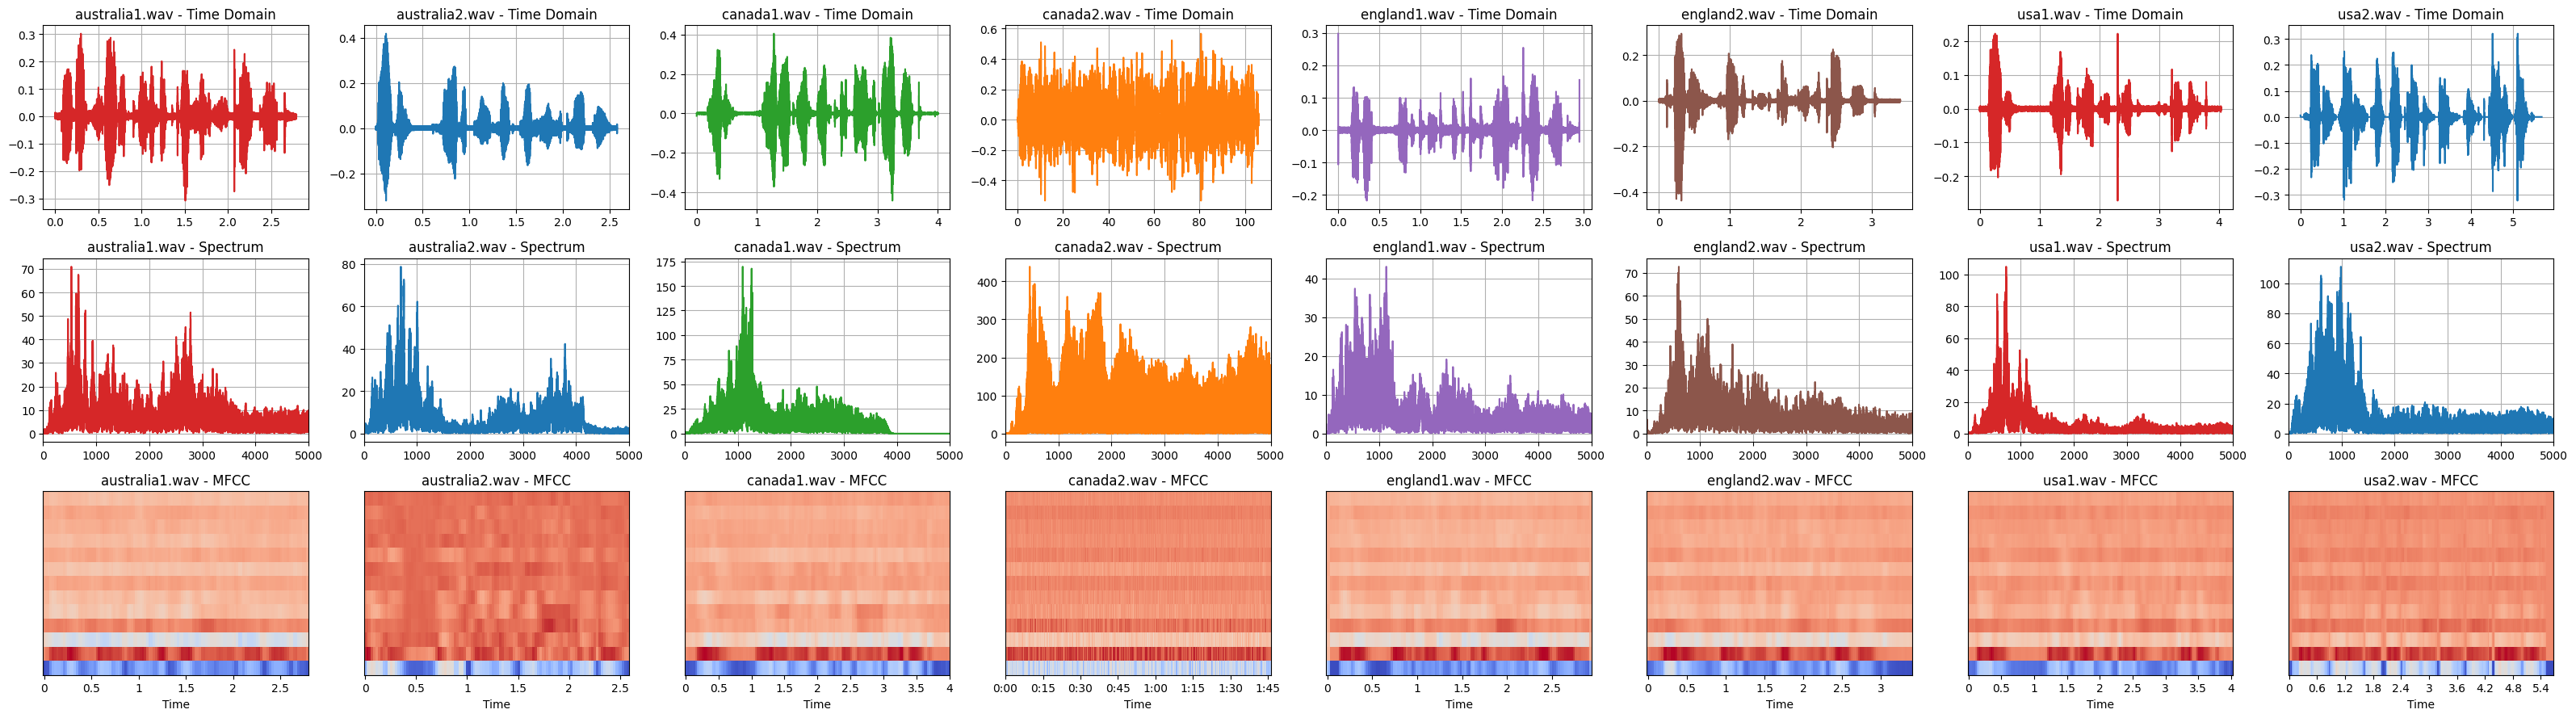


=== 5. VISUAL ANALYSIS PER-ACCENT (file columns + aggregated) ===


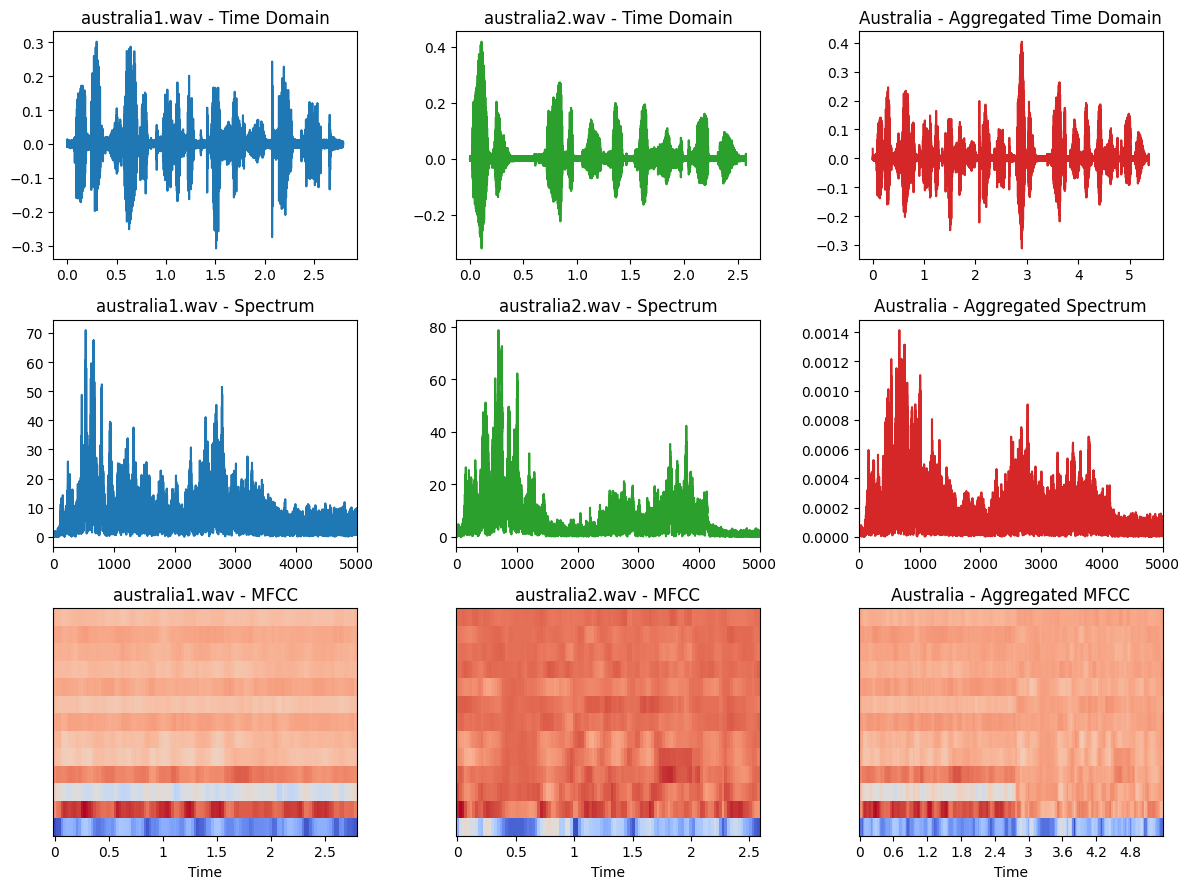

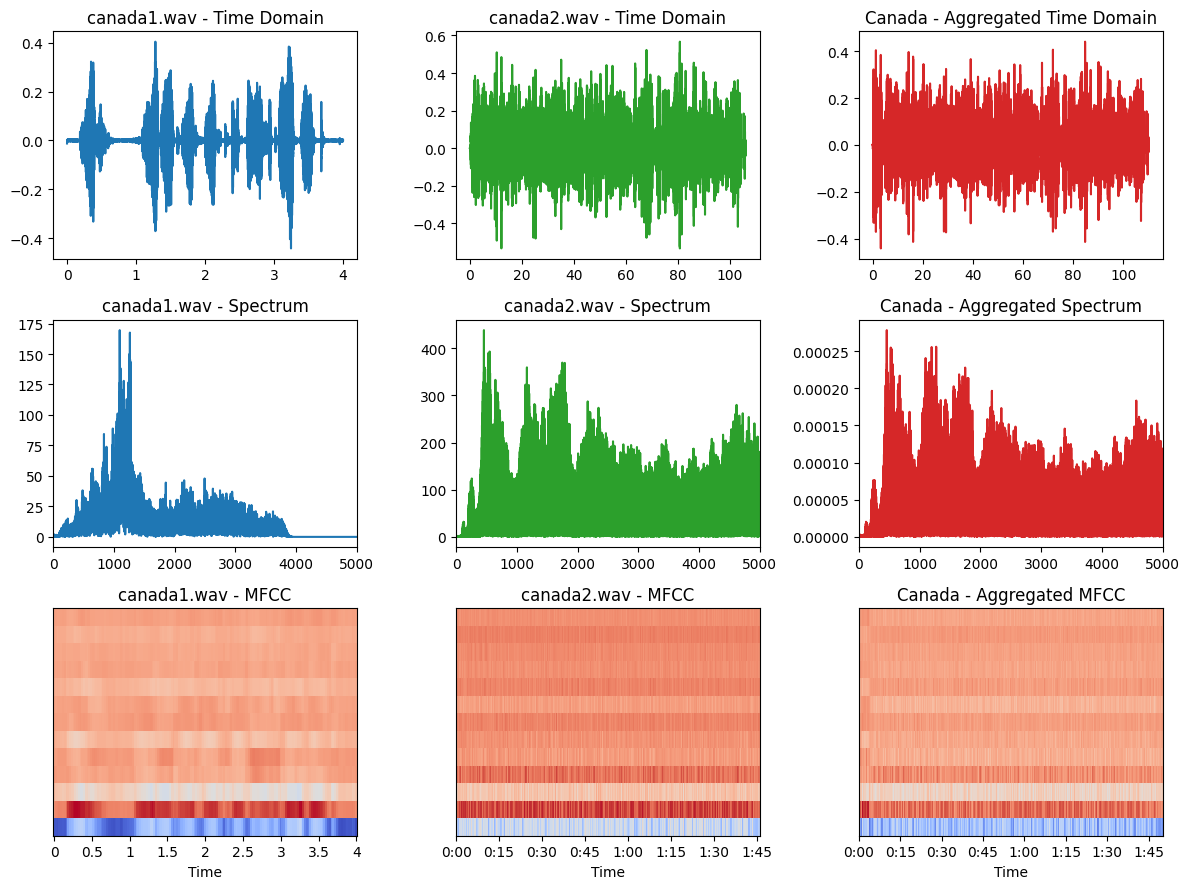

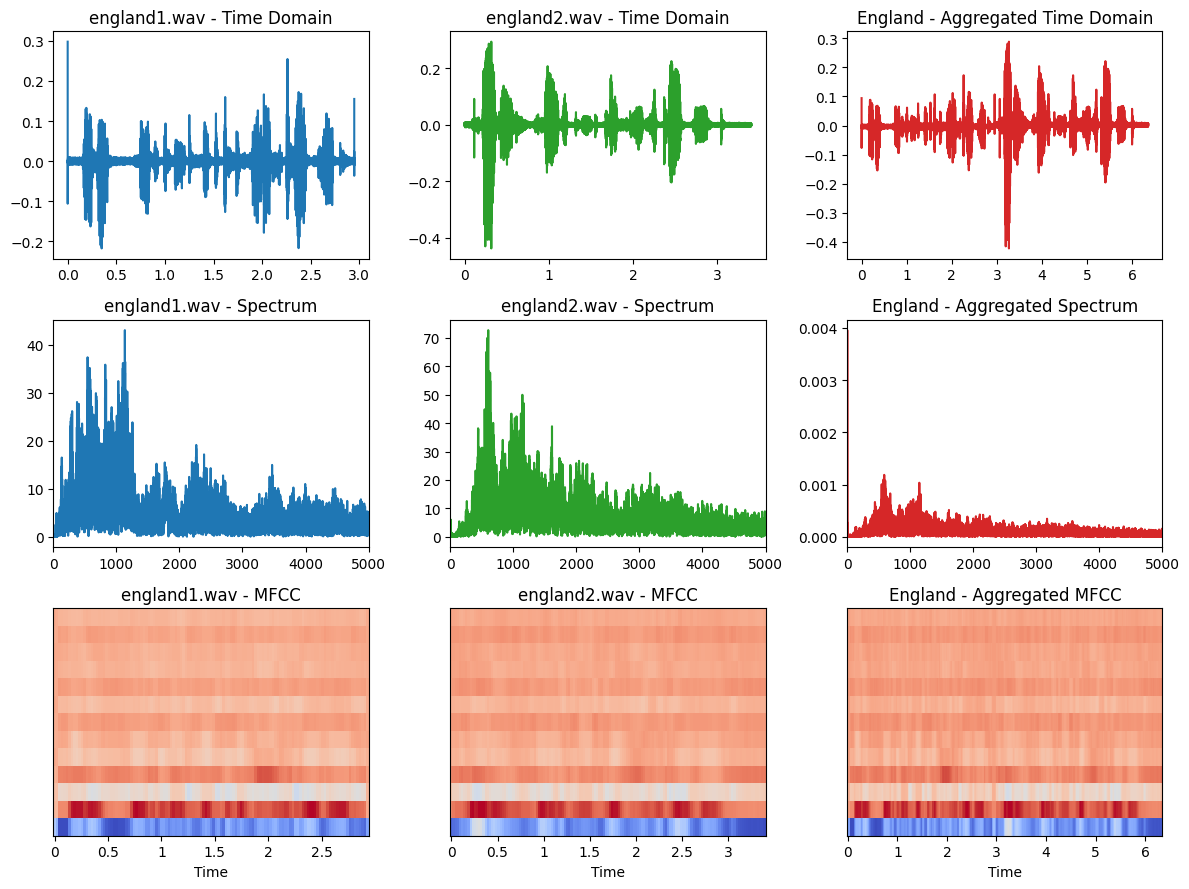

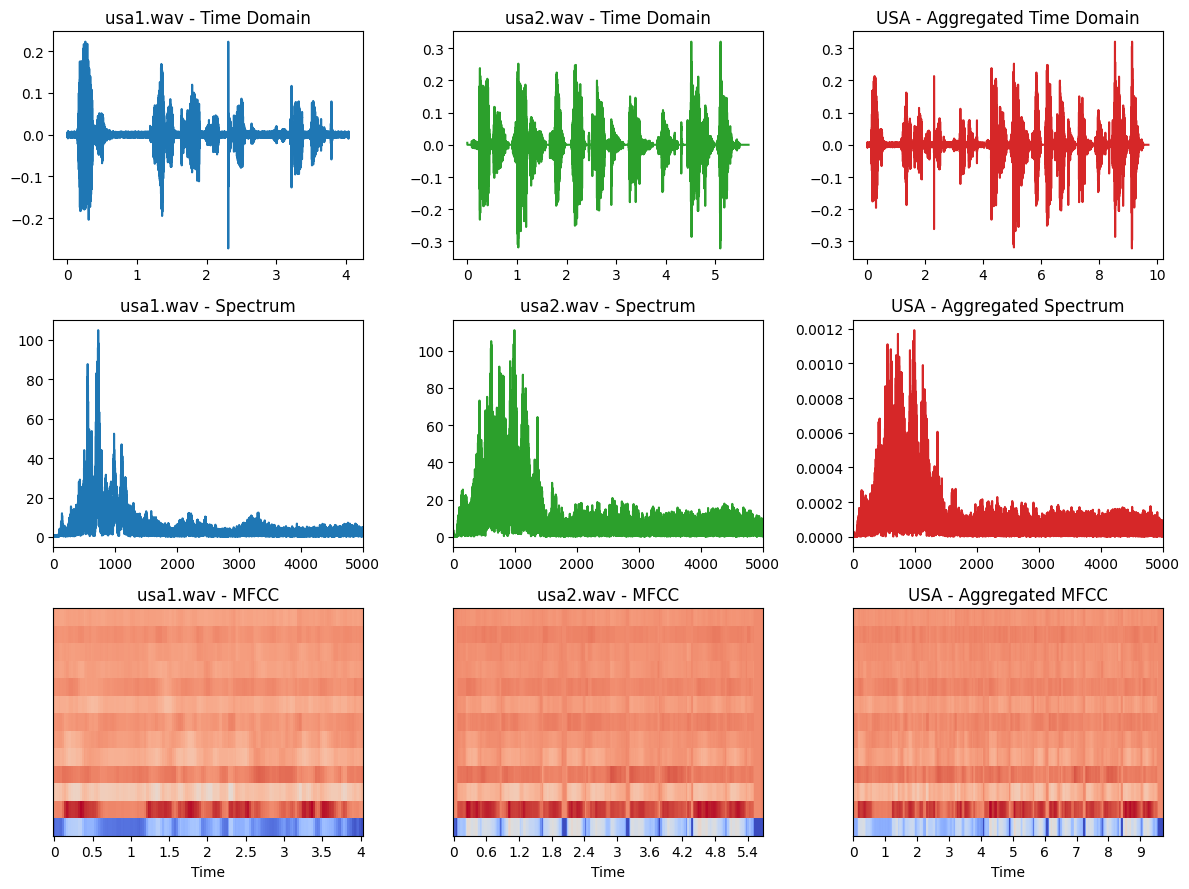


=== 6. COMPARATIVE PLOTS ===


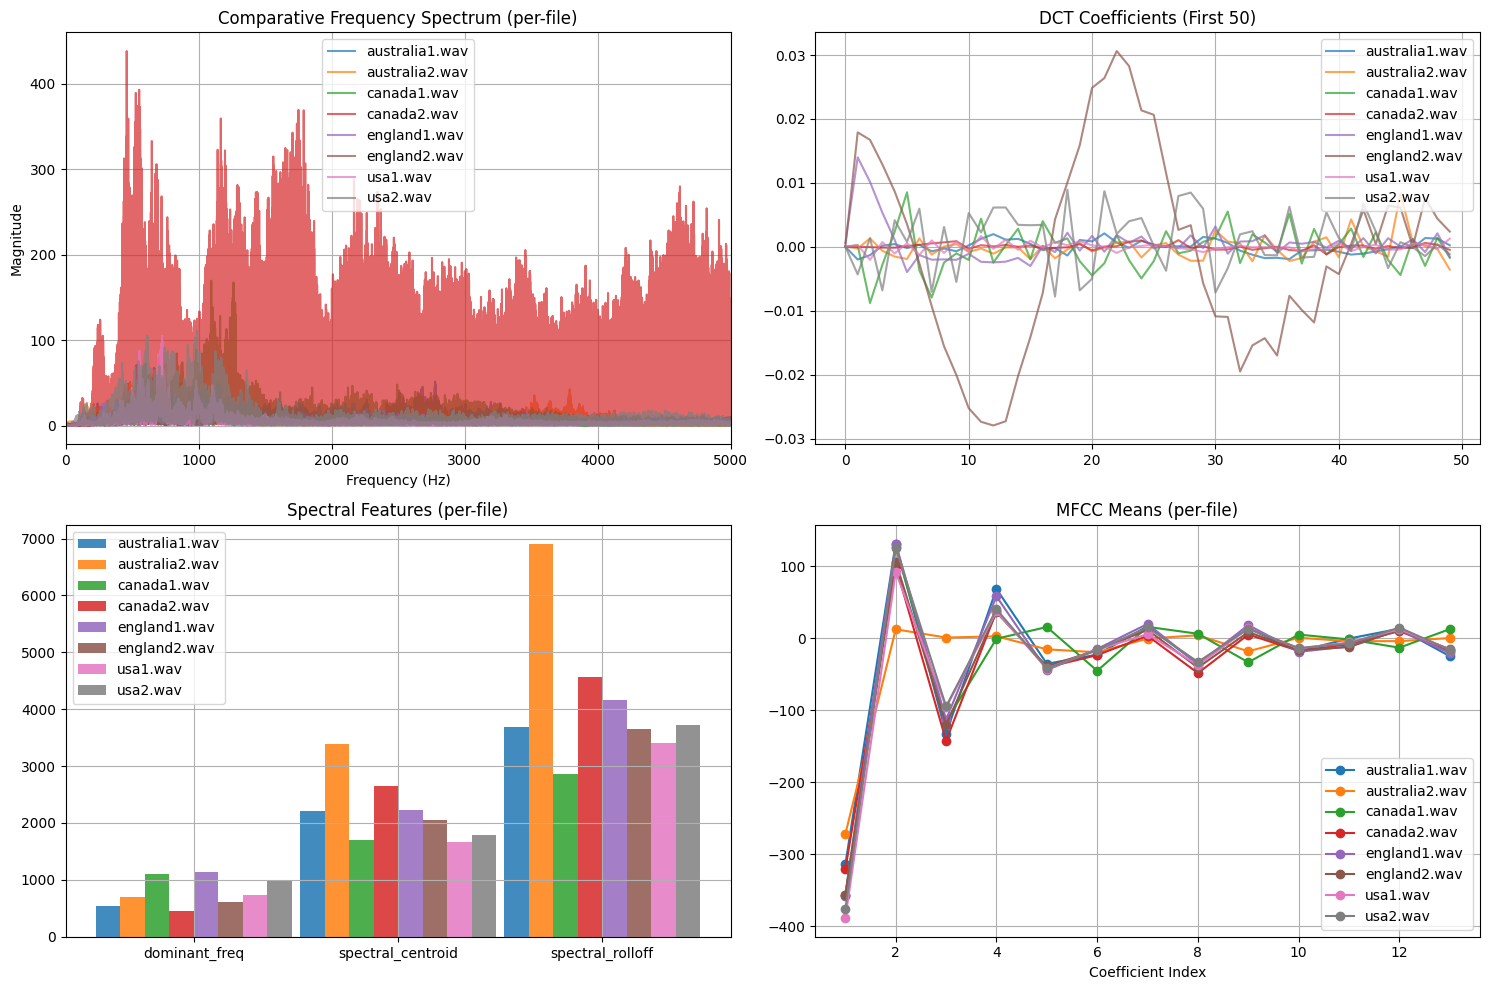

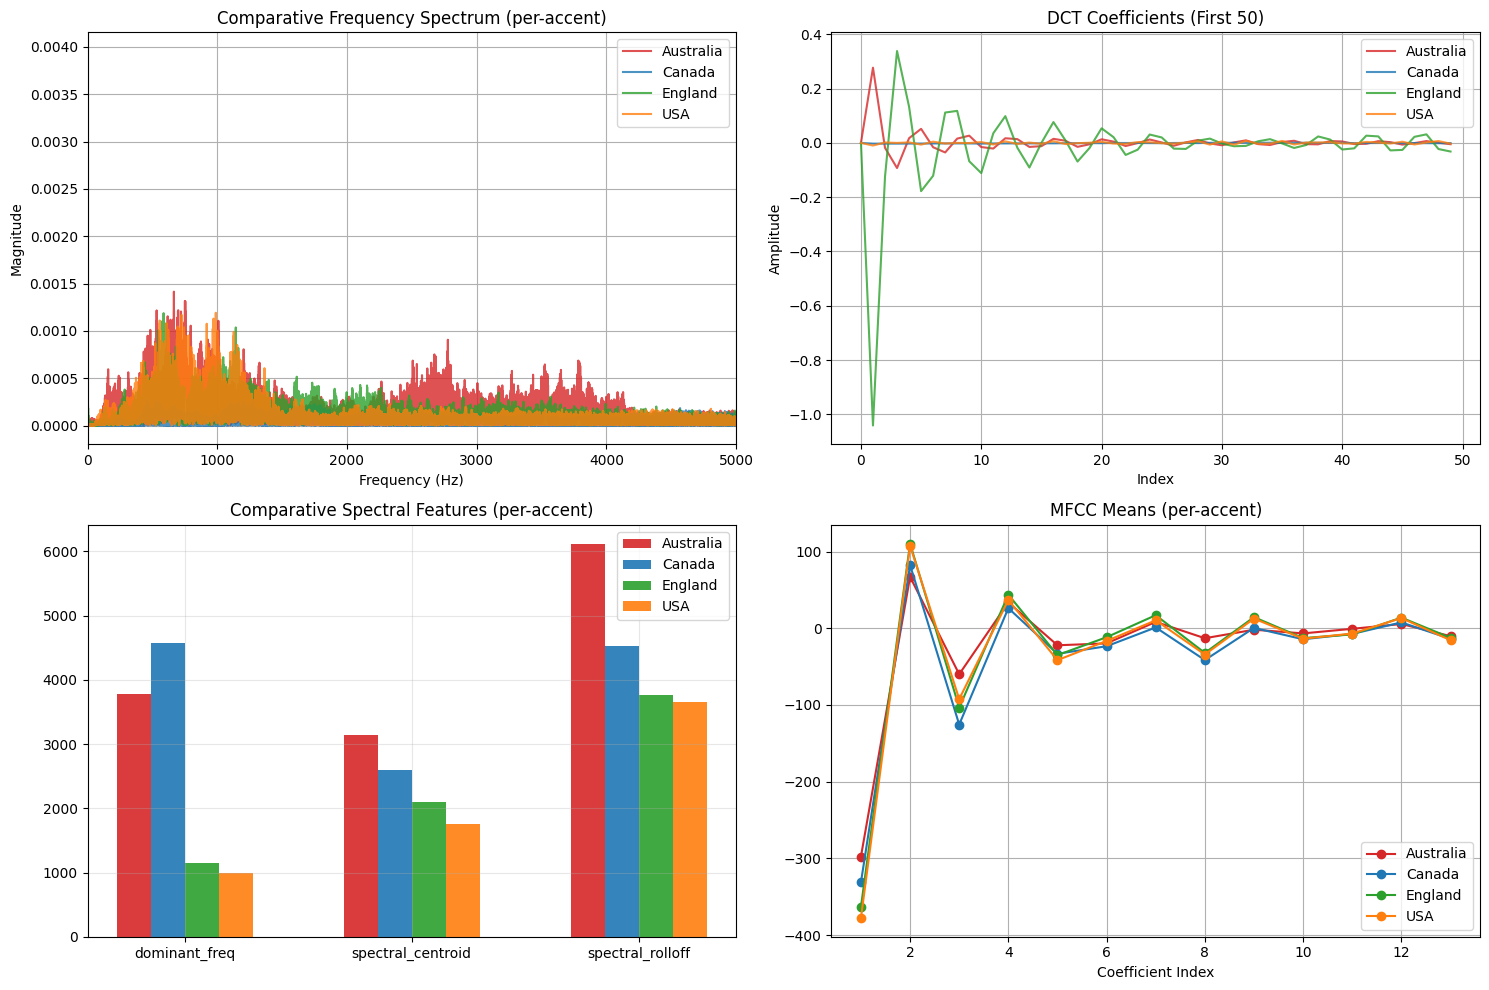


=== 7. PERBANDINGAN TIAP FILE DI DALAM MASING-MASING NEGARA (Waveform, FFT, MFCC, DCT) ===

=== Perbandingan Australia: australia1.wav vs australia2.wav ===


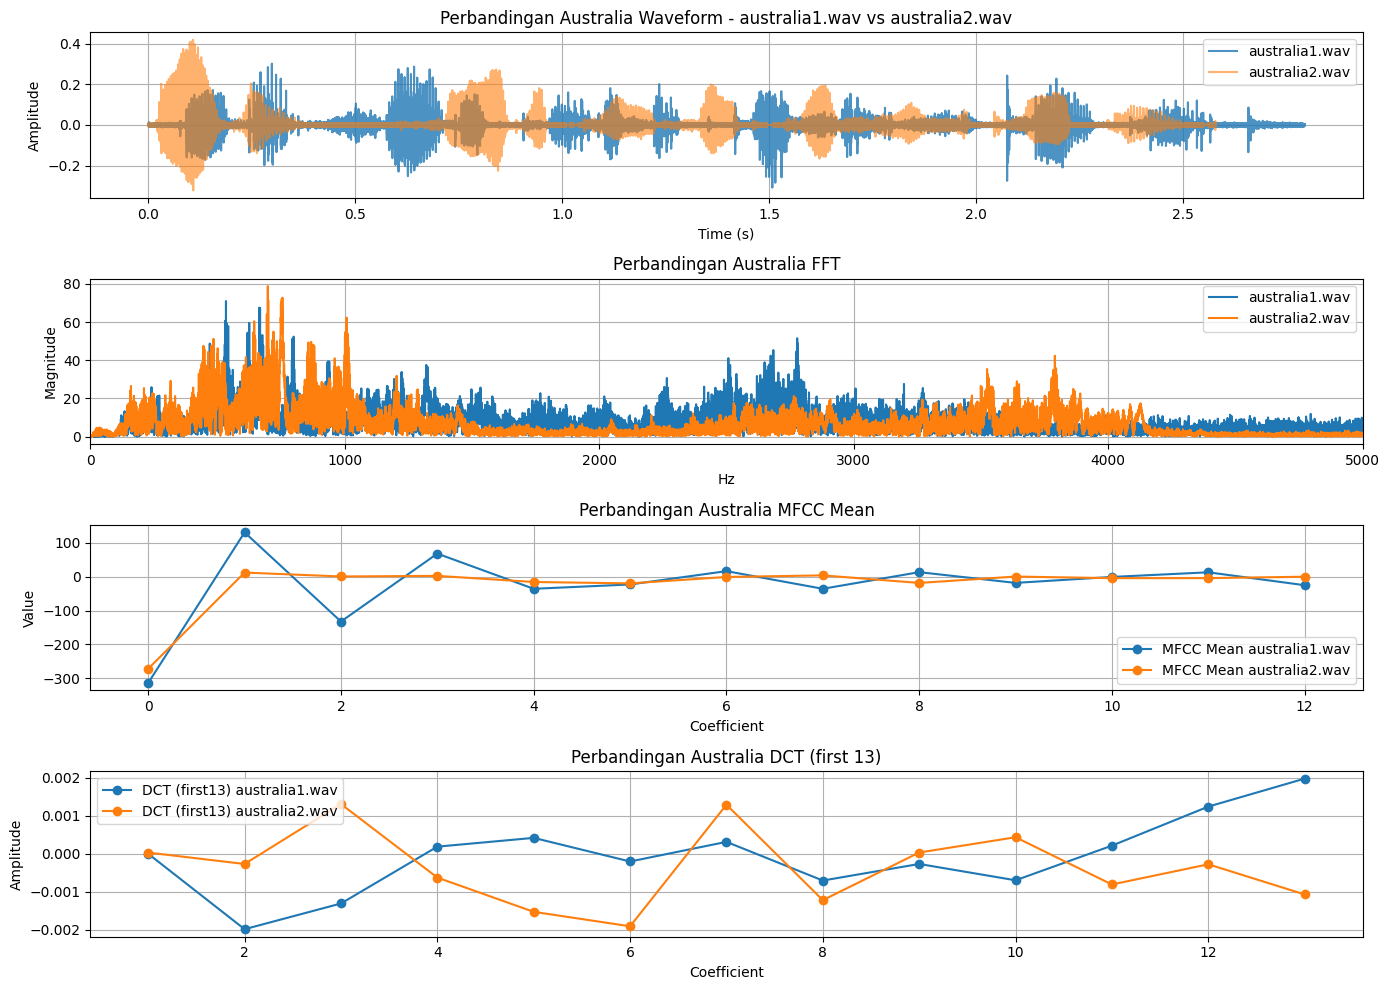


=== Perbandingan Canada: canada1.wav vs canada2.wav ===


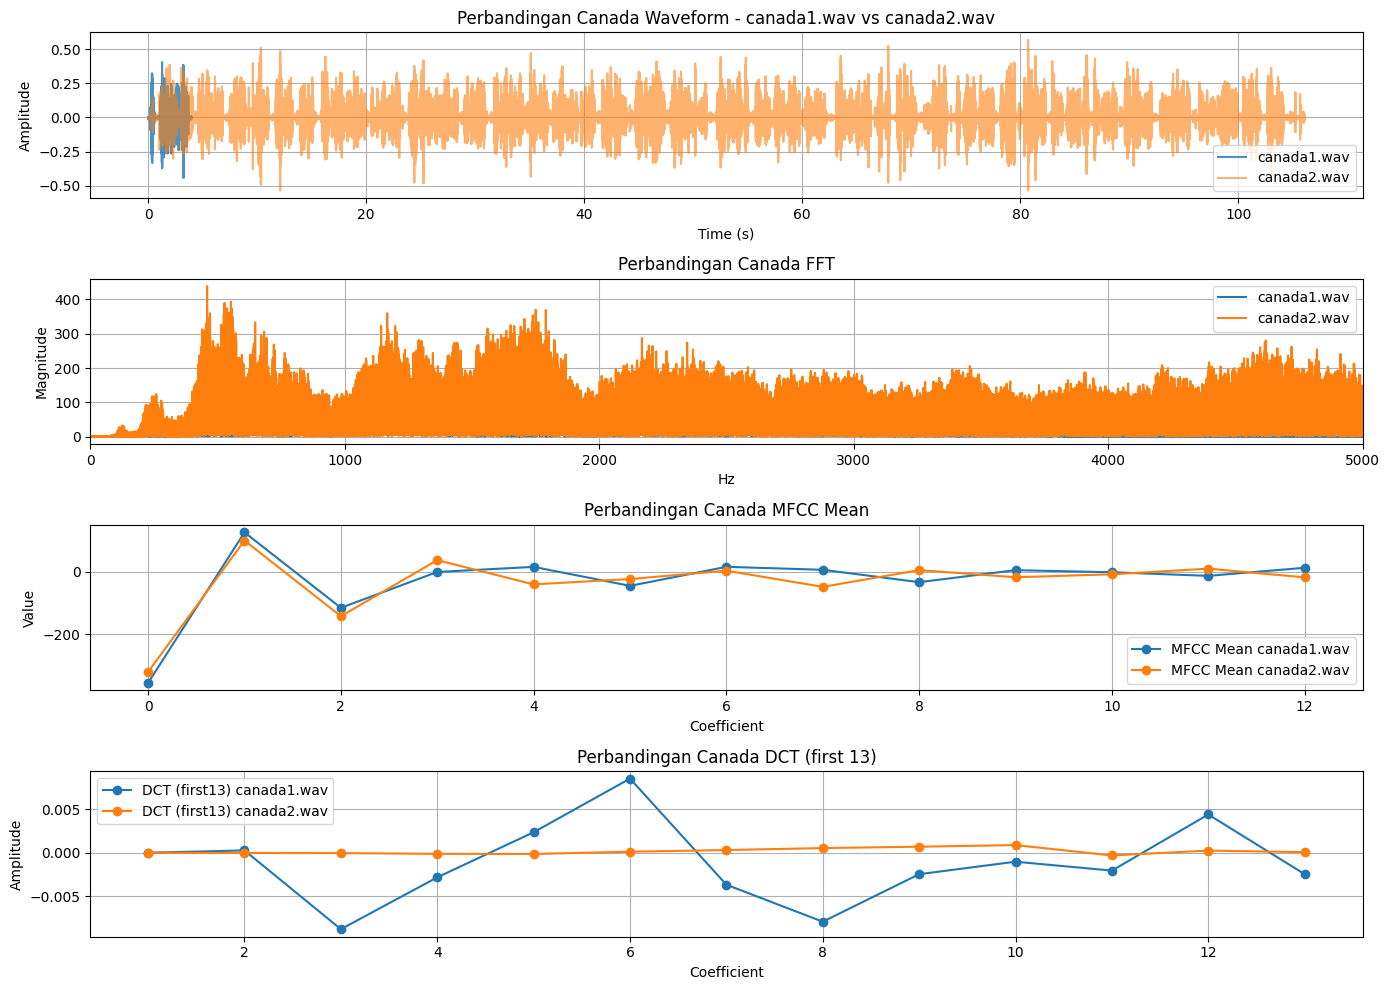


=== Perbandingan England: england1.wav vs england2.wav ===


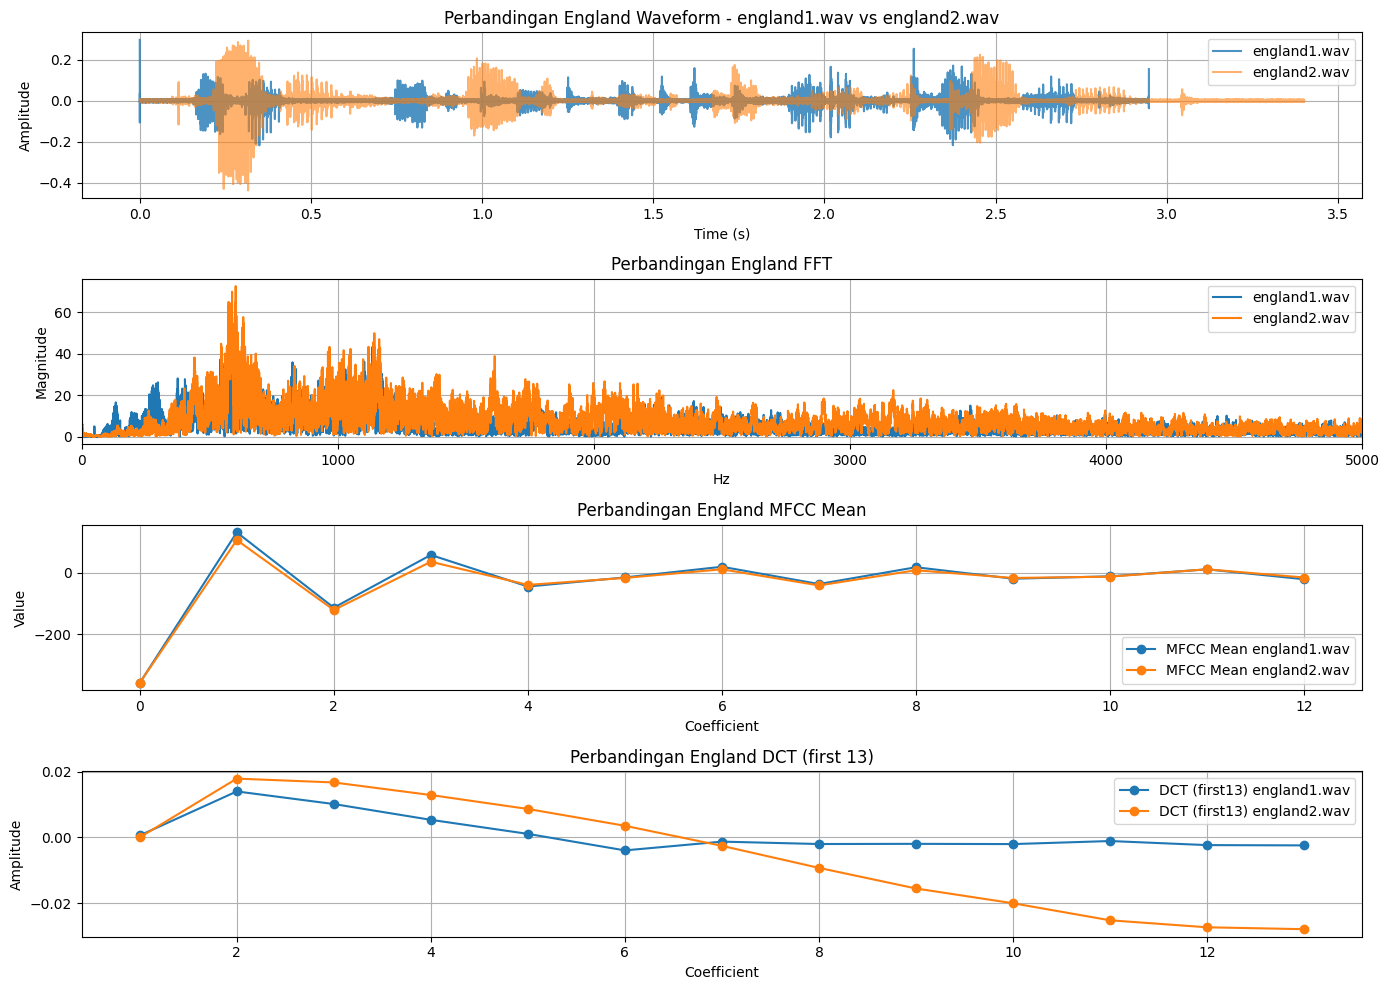


=== Perbandingan USA: usa1.wav vs usa2.wav ===


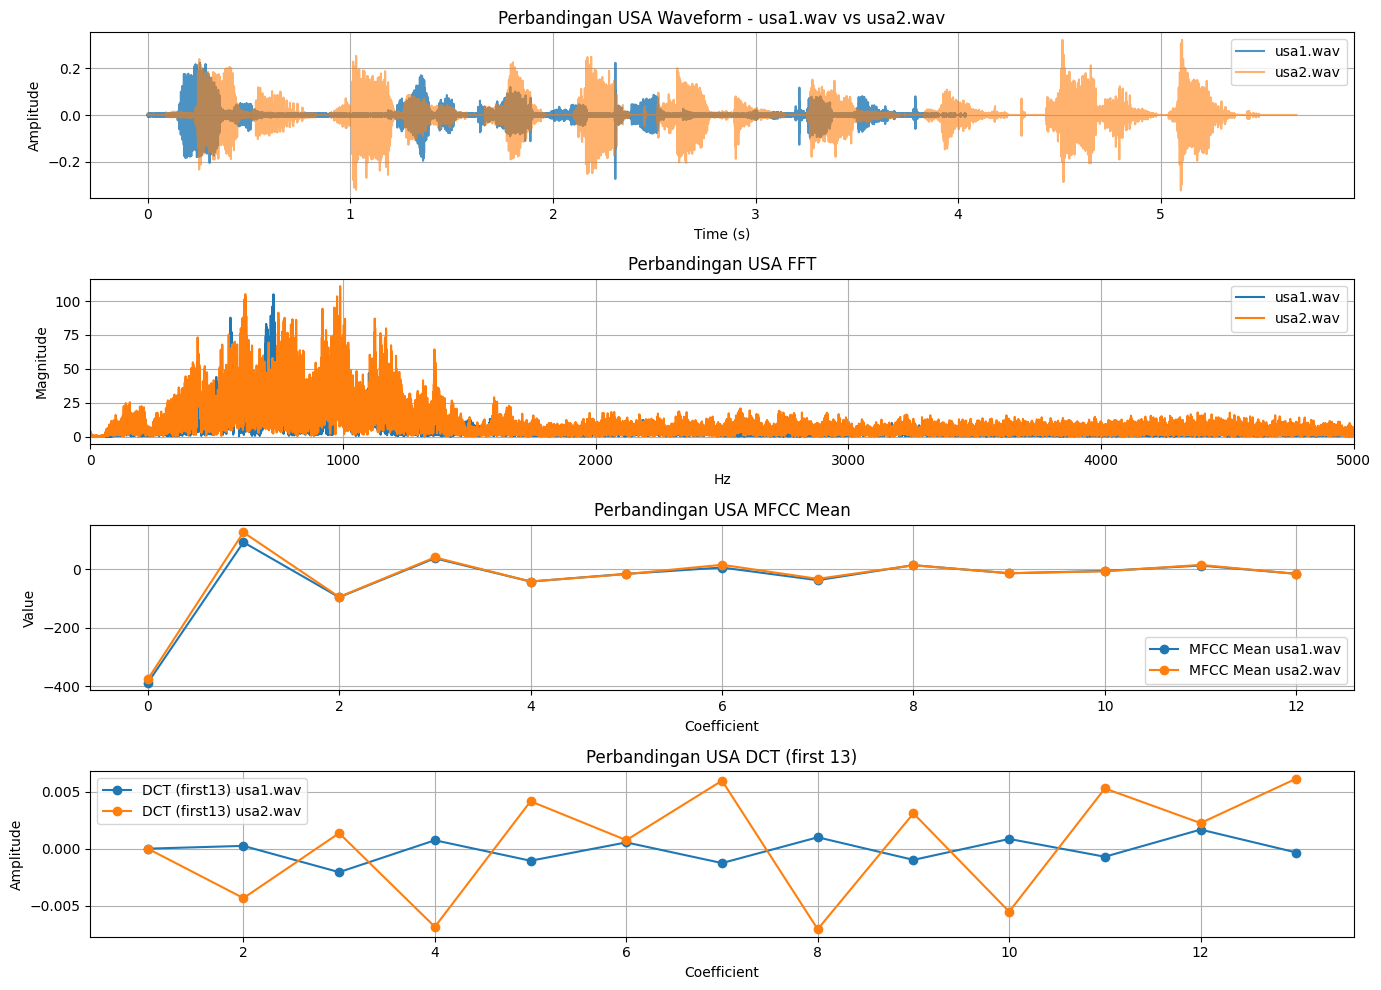


=== 8. TRAIN CLASSIFIER (per-file features) ===
Trained classifier on 8 files. Labels: ['Australia', 'Canada', 'England', 'USA']

=== 9. DEMO PREDICTIONS PER-FILE ===

File: australia1.wav
  Expected: Australia  Predicted: England
   Australia: 0.000
   Canada: 0.000
   England: 1.000
   USA: 0.000

File: australia2.wav
  Expected: Australia  Predicted: Australia
   Australia: 1.000
   Canada: 0.000
   England: 0.000
   USA: 0.000

File: canada1.wav
  Expected: Canada  Predicted: Canada
   Australia: 0.000
   Canada: 1.000
   England: 0.000
   USA: 0.000

File: canada2.wav
  Expected: Canada  Predicted: England
   Australia: 0.000
   Canada: 0.000
   England: 1.000
   USA: 0.000

File: england1.wav
  Expected: England  Predicted: England
   Australia: 0.000
   Canada: 0.000
   England: 1.000
   USA: 0.000

File: england2.wav
  Expected: England  Predicted: England
   Australia: 0.000
   Canada: 0.000
   England: 1.000
   USA: 0.000

File: usa1.wav
  Expected: USA  Predicted: USA
   Au

,File,Expected,Predicted,Prob_Australia,Prob_Canada,Prob_England,Prob_USA
0,australia1.wav,Australia,England,0.0,0.0,1.0,0.0
1,australia2.wav,Australia,Australia,1.0,0.0,0.0,0.0
2,canada1.wav,Canada,Canada,0.0,1.0,0.0,0.0
3,canada2.wav,Canada,England,0.0,0.0,1.0,0.0
4,england1.wav,England,England,0.0,0.0,1.0,0.0
5,england2.wav,England,England,0.0,0.0,1.0,0.0
6,usa1.wav,USA,USA,0.0,0.0,0.0,1.0
7,usa2.wav,USA,USA,0.0,0.0,0.0,1.0



=== SELESAI ===


In [ ]:
if __name__ == "__main__":
    audio_files = [
        'australia1.wav','australia2.wav',
        'canada1.wav','canada2.wav',
        'england1.wav','england2.wav',
        'usa1.wav','usa2.wav'
    ]

    file_to_accent = {
        'australia1.wav':'Australia','australia2.wav':'Australia',
        'canada1.wav':'Canada','canada2.wav':'Canada',
        'england1.wav':'England','england2.wav':'England',
        'usa1.wav':'USA','usa2.wav':'USA'
    }

    analyzer = PerCountryAnalyzer(sample_rate=22050, accents=['Australia','Canada','England','USA'])

    print("\n=== 1. LOAD FILES (WITH GROUPING) ===")
    analyzer.load_audio_files(audio_files, group_per_accent=True, mapping=file_to_accent)

    print("\n=== 2. EXTRACT PER-FILE FEATURES ===")
    analyzer.extract_all_file_features()
    df_file = analyzer.get_file_features_df()
    if not df_file.empty:
        display(df_file)

    print("\n=== 3. EXTRACT AGGREGATED PER-ACCENT FEATURES ===")
    analyzer.extract_accent_aggregates()
    df_accent = analyzer.get_accent_features_df()
    if not df_accent.empty:
        display(df_accent)

    print("\n=== 4. VISUAL ANALYSIS PER-FILE (grid) ===")
    analyzer.plot_per_file_grid()

    print("\n=== 5. VISUAL ANALYSIS PER-ACCENT (file columns + aggregated) ===")
    for accent in analyzer.accent_signals.keys():
        analyzer.plot_accent_comparison(accent)

    print("\n=== 6. COMPARATIVE PLOTS ===")
    analyzer.plot_combined_analysis()
    analyzer.plot_combined_analysis(accent_level=True)

    print("\n=== 7. PERBANDINGAN TIAP FILE DI DALAM MASING-MASING NEGARA (Waveform, FFT, MFCC, DCT) ===")
    analyzer.compare_all_countries()

    print("\n=== 8. TRAIN CLASSIFIER (per-file features) ===")
    knn, scaler = analyzer.create_classifier_from_labels(file_to_accent, k=1)

    print("\n=== 9. DEMO PREDICTIONS PER-FILE ===")
    prediction_rows = []
    ordered_labels = analyzer.trained_labels
    for fp in audio_files:
        pred, probs = analyzer.detect_accent(fp)
        row = {'File': fp, 'Expected': file_to_accent.get(fp, ''), 'Predicted': pred}
        for i, lab in enumerate(ordered_labels):
            row[f'Prob_{lab}'] = float(probs[i]) if i < len(probs) else 0.0
        prediction_rows.append(row)
        print(f"\nFile: {fp}\n  Expected: {file_to_accent.get(fp)}  Predicted: {pred}")
        for i, lab in enumerate(ordered_labels):
            print(f"   {lab}: {float(probs[i]):.3f}")
    df_pred = pd.DataFrame(prediction_rows)
    display(df_pred.round(3))

    print("\n=== SELESAI ===")

In [ ]:
# === SAVE HASIL TABEL KE xlsx ===

# 1. Simpan fitur per-file
try:
    df_file.to_excel("features_per_file.xlsx", index=False)
    print("Saved: features_per_file.xlsx")
except Exception as e:
    print("Gagal menyimpan features_per_file.xlsx:", e)

Saved: features_per_file.xlsx


In [ ]:
# 2. Simpan fitur per-accent
try:
    df_accent.to_excel("features_per_accent.xlsx", index=False)
    print("Saved: features_per_accent.xlsx")
except Exception as e:
    print("Gagal menyimpan features_per_accent.xlsx:", e)

Saved: features_per_accent.xlsx


In [ ]:
# 3. Simpan hasil prediksi
try:
    df_pred.to_excel("accent_predictions.xlsx", index=False)
    print("Saved: accent_predictions.xlsx")
except Exception as e:
    print("Gagal menyimpan accent_predictions.xlsx:", e)

Saved: accent_predictions.xlsx
